# 3 and 4 elements in the challenge box (step 6) — results

Reads the outputs of `campaign_b.py` (B3: 3-element grid at 0.90 and 1.00 GHz; B4: 4-element Bayesian optimisation) and of
`exploration_sweep.py` (sweep A: 2 elements). No computation here.

* maps of G (kit components, best fed element), η and G/G_max over (d₁, d₂) for B3;
* B4 convergence (robust objective per evaluation and best so far);
* gain vs frequency around f₀ for the checked best points (components frozen);
* comparison table 2 / 3 / 4 elements: G, G_r(50 Ω), D, η, Harrington's normal gain, frequency sensitivity, components.

G: gain with ideal matching, +y, φ polarisation. Robust: mean over α_cal × {0.85, 1, 1.15} × kit tolerance {−, 0, +}.
Folders: `EXPLORATION_DIR` (data) and `EXPLORATION_FIG_DIR` (PNG) environment variables, else the PUBLICATIONS `exploration/` folder.

In [1]:
%matplotlib inline
import csv, json, os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = Path(os.environ.get('EXPLORATION_DIR', r'D:\PhD_Fahdilou_Leat\PUBLICATIONS\7-EurAAP Small Antenna Super-Gain Challenge\exploration'))
FIG_DIR = Path(os.environ.get('EXPLORATION_FIG_DIR', DATA_DIR / 'figures'))
FIG_DIR.mkdir(parents=True, exist_ok=True)
C0 = 1 / np.sqrt(8.854e-12 * 1.257e-6)
BOX_A = np.hypot(0.187 / 2, 0.125 / 2)          # radius of the sphere enclosing the 187 x 125 mm box

def harrington_db(f_ghz):
    """Normal gain (ka)^2 + 2 ka of the minimum sphere of the box."""
    ka = 2 * np.pi * f_ghz * 1e9 / C0 * BOX_A
    return 10 * np.log10(ka ** 2 + 2 * ka), ka

def read_jsonl(p):
    return [json.loads(l) for l in open(p, encoding='utf-8') if l.strip()] if p.is_file() else []

def read_csv(p):
    def num(v):
        try:
            return float(v)
        except ValueError:
            return {'True': True, 'False': False}.get(v, v)
    if not p.is_file():
        return []
    with open(p, newline='', encoding='utf-8') as fh:
        return [{k: num(v) for k, v in r.items()} for r in csv.DictReader(fh)]

B3 = read_jsonl(DATA_DIR / 'B3_designs.jsonl')
B4 = read_jsonl(DATA_DIR / 'B4_designs.jsonl')
B4_hist = json.loads((DATA_DIR / 'B4_bo_history.json').read_text()) if (DATA_DIR / 'B4_bo_history.json').is_file() else None
checks = {c: json.loads((DATA_DIR / f'{c}_checks.json').read_text()) if (DATA_DIR / f'{c}_checks.json').is_file() else []
          for c in ('B3', 'B4')}
A2 = read_csv(DATA_DIR / 'sweepA_w4mm.csv')
print(f'sweep A: {len(A2)} rows | B3: {len(B3)} records | B4: {len(B4)} records, '
      f"{len(B4_hist['records']) if B4_hist else 0} BO evaluations | checks: B3 {len(checks['B3'])}, B4 {len(checks['B4'])}")
for f in (0.9, 1.0):
    g, ka = harrington_db(f)
    print(f'Harrington normal gain at {f:.2f} GHz: ka = {ka:.2f}, G_N = {g:.2f} dBi')

INK, INK_2, MUTED, GRID, AXIS, SURFACE = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#fcfcfb'
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
plt.rcParams.update({'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
                     'axes.edgecolor': AXIS, 'axes.labelcolor': INK_2, 'xtick.color': MUTED, 'ytick.color': MUTED,
                     'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.spines.top': False,
                     'axes.spines.right': False, 'lines.linewidth': 1.6, 'legend.frameon': False,
                     'font.size': 9, 'axes.titlesize': 10, 'figure.dpi': 110})

def mm(spacings):
    return '/'.join(f'{round(d, 1):g}' for d in spacings)


def show(fig, name, legend=True, ncol=3):
    if legend:
        handles, labels = [], []
        for ax in fig.axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                if l not in labels and not l.startswith('_'):
                    handles.append(h); labels.append(l)
        if labels:
            fig.legend(handles, labels, loc='lower center', ncol=ncol)
            n_rows = int(np.ceil(len(labels) / ncol))
            fig.tight_layout(rect=(0, min(0.6, (0.3 + 0.2 * n_rows) / fig.get_figheight()), 1, 1))
        else:
            fig.tight_layout()
    else:
        fig.tight_layout()
    fig.savefig(FIG_DIR / name, dpi=150)
    print('saved', FIG_DIR / name)
    plt.show()

sweep A: 198 rows | B3: 270 records | B4: 180 records, 45 BO evaluations | checks: B3 6, B4 3
Harrington normal gain at 0.90 GHz: ka = 2.12, G_N = 9.42 dBi
Harrington normal gain at 1.00 GHz: ka = 2.36, G_N = 10.12 dBi


## B3 — maps over (d₁, d₂), best fed element at each geometry (kit components, α_cal)

saved D:\PhD_Fahdilou_Leat\PUBLICATIONS\7-EurAAP Small Antenna Super-Gain Challenge\exploration\figures\B3_maps_0.90GHz.png


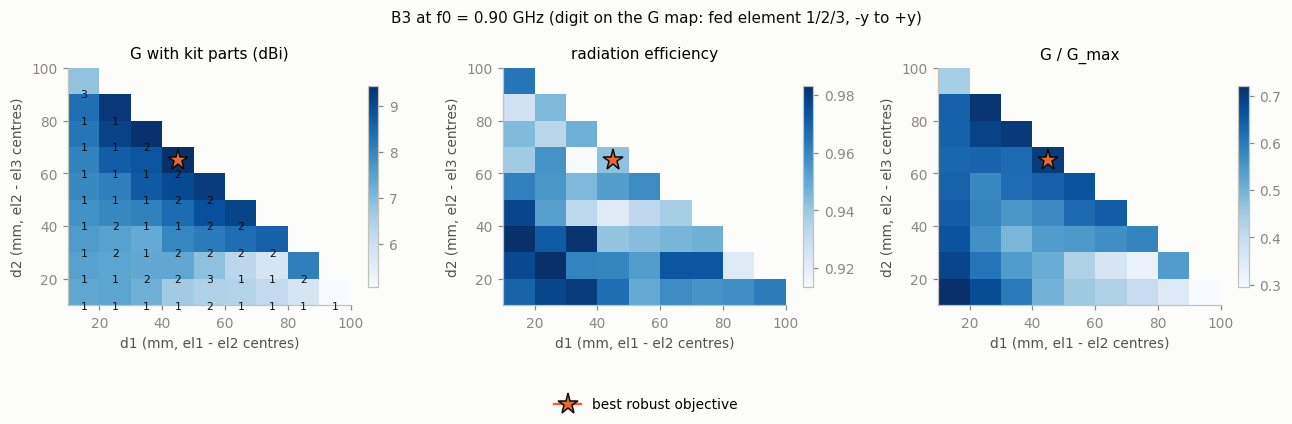

saved D:\PhD_Fahdilou_Leat\PUBLICATIONS\7-EurAAP Small Antenna Super-Gain Challenge\exploration\figures\B3_maps_1.00GHz.png


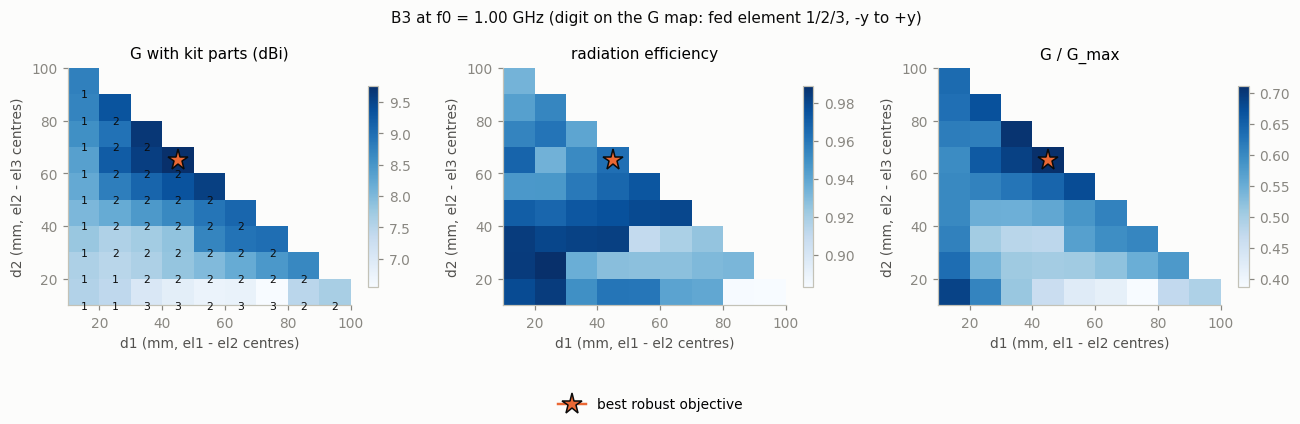

In [2]:
if not B3:
    print('No B3 results yet (run campaign_b.py b3).')
for f in sorted({r['f0_GHz'] for r in B3}):
    best = [r for r in B3 if r['best_fed'] and r['f0_GHz'] == f]
    d1s = sorted({r['spacings_mm'][0] for r in best}); d2s = sorted({r['spacings_mm'][1] for r in best})
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
    for ax, key, title, cmap in zip(axes, ('G_kit_dBi', 'eta', 'G_over_G_max'),
                                    ('G with kit parts (dBi)', 'radiation efficiency', 'G / G_max'),
                                    ('Blues', 'Blues', 'Blues')):
        M = np.full((len(d2s), len(d1s)), np.nan)
        for r in best:
            M[d2s.index(r['spacings_mm'][1]), d1s.index(r['spacings_mm'][0])] = r[key]
        im = ax.pcolormesh(d1s, d2s, M, shading='nearest', cmap=cmap)
        fig.colorbar(im, ax=ax, shrink=0.85)
        ax.set_xlabel('d1 (mm, el1 - el2 centres)'); ax.set_ylabel('d2 (mm, el2 - el3 centres)')
        ax.set_title(title); ax.grid(False)
    top = max(best, key=lambda r: r['objective'])
    for ax in axes:
        ax.plot(*top['spacings_mm'], marker='*', ms=14, color=SERIES[1], mec=INK, label='best robust objective')
    for r in best:                      # fed element index, offset so the star does not hide it
        axes[0].annotate(r['fed'][-1], r['spacings_mm'], xytext=(0, -9), textcoords='offset points',
                         ha='center', va='center', fontsize=7, color=INK)
    fig.suptitle(f'B3 at f0 = {f:.2f} GHz (digit on the G map: fed element 1/2/3, -y to +y)', fontsize=10, color=INK)
    show(fig, f'B3_maps_{f:.2f}GHz.png')

## B4 — Bayesian optimisation convergence

saved D:\PhD_Fahdilou_Leat\PUBLICATIONS\7-EurAAP Small Antenna Super-Gain Challenge\exploration\figures\B4_convergence.png


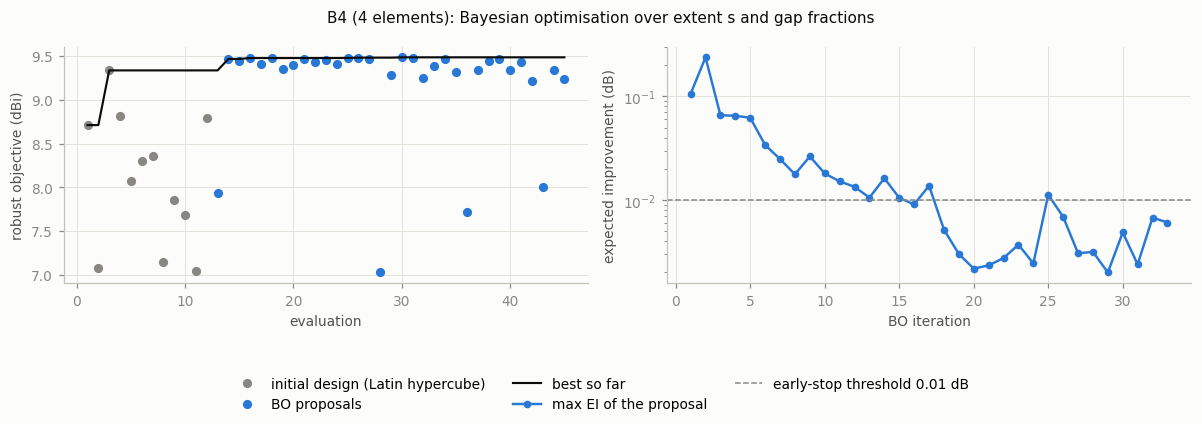

In [3]:
if not B4_hist:
    print('No B4 history yet (run campaign_b.py b4).')
else:
    rec = B4_hist['records']
    n = np.arange(1, len(rec) + 1)
    y = np.array([r['y'] for r in rec])
    init = np.array([r['phase'] == 'init' for r in rec])
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    axes[0].plot(n[init], y[init], 'o', ms=5, color=MUTED, label='initial design (Latin hypercube)')
    axes[0].plot(n[~init], y[~init], 'o', ms=5, color=SERIES[0], label='BO proposals')
    axes[0].plot(n, np.maximum.accumulate(y), color=INK, lw=1.4, label='best so far')
    axes[0].set_xlabel('evaluation'); axes[0].set_ylabel('robust objective (dBi)')
    ei = [r['ei'] for r in rec if r['phase'] == 'bo']
    if ei:
        axes[1].semilogy(np.arange(1, len(ei) + 1), np.maximum(ei, 1e-6), 'o-', ms=4, color=SERIES[0], label='max EI of the proposal')
        axes[1].axhline(0.01, color=MUTED, ls='--', lw=1, label='early-stop threshold 0.01 dB')
        axes[1].set_xlabel('BO iteration'); axes[1].set_ylabel('expected improvement (dB)')
    fig.suptitle('B4 (4 elements): Bayesian optimisation over extent s and gap fractions', fontsize=10, color=INK)
    show(fig, 'B4_convergence.png')

## Gain vs frequency around f₀ (components frozen), checked best points

saved D:\PhD_Fahdilou_Leat\PUBLICATIONS\7-EurAAP Small Antenna Super-Gain Challenge\exploration\figures\B3_B4_G_vs_f.png


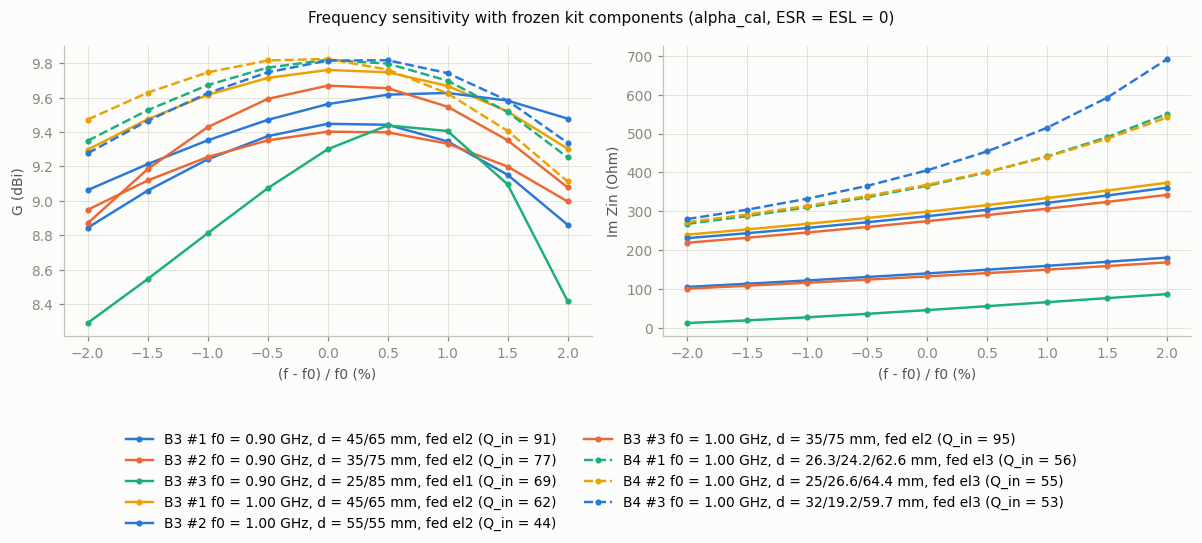

In [4]:
pts = [(c, k) for c in ('B3', 'B4') for k in checks[c]]
if not pts:
    print('No post-checks yet.')
else:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.9 + 0.2 * np.ceil(len(pts) / 2)))
    for i, (camp, k) in enumerate(pts):
        off = [r['offset_pct'] for r in k['freq_rows']]
        lab = f"{camp} #{k['rank']} f0 = {k['f0_GHz']:.2f} GHz, d = {mm(k['spacings_mm'])} mm, fed {k['fed']} (Q_in = {k['Q_in']:.0f})"
        col = SERIES[i % len(SERIES)]
        ls = '-' if camp == 'B3' else '--'
        axes[0].plot(off, [r['G_dBi'] for r in k['freq_rows']], marker='o', ms=3, color=col, ls=ls, label=lab)
        axes[1].plot(off, [r['Zin_im_ohm'] for r in k['freq_rows']], marker='o', ms=3, color=col, ls=ls, label=lab)
    axes[0].set_ylabel('G (dBi)'); axes[1].set_ylabel('Im Zin (Ohm)')
    for ax in axes:
        ax.set_xlabel('(f - f0) / f0 (%)')
    fig.suptitle('Frequency sensitivity with frozen kit components (alpha_cal, ESR = ESL = 0)', fontsize=10, color=INK)
    show(fig, 'B3_B4_G_vs_f.png', ncol=2)

## Comparison 2 / 3 / 4 elements

2 elements: sweep A (continuous loads, no kit snapping). 3 and 4 elements: best robust design per f₀ (kit parts).
ΔG(±1 %): worst gain change at f₀ × (1 ± 1 %) with frozen parts (from the post-checks).

 K    f0               geometry  fed      G  G_rob    G_r      D    eta  G-G_N  G_max  dG(1%)  Q_in  dG_ESR  components
 2  0.90              d = 25 mm  el1   7.37    nan   2.65   7.54  0.960  -2.05    nan    +nan   nan    +nan  1.559 pF (continuous)
 3  0.90           d = 45/65 mm  el2   9.45   9.40  -1.07   9.71  0.942  +0.03  11.00   -0.21    91   -0.12  el1 2.7 pF (+-4%), el3 1.2 pF (+-8%)
 2  1.00              d = 25 mm  el1   7.52    nan   0.31   7.64  0.971  -2.60    nan    +nan   nan    +nan  0.6712 pF (continuous)
 3  1.00           d = 45/65 mm  el2   9.76   9.47  -2.73   9.92  0.963  -0.36  11.24   -0.14    62   -0.06  el1 1 pF (+-10%), el3 0.5 pF (+-20%)
 4  1.00  d = 26.3/24.2/62.6 mm  el3   9.82   9.49  -1.22   9.96  0.968  -0.30  11.42   -0.15    56   -0.07  el1 1 pF (+-10%), el2 0.3 pF (+-33%), el4 0.5 pF (+-20%)
dG(1%): worst gain change at f0 +- 1 % (frozen parts); dG_ESR: worst change over ESR <= 0.3 Ohm, ESL <= 1 nH


saved D:\PhD_Fahdilou_Leat\PUBLICATIONS\7-EurAAP Small Antenna Super-Gain Challenge\exploration\figures\G_vs_K.png


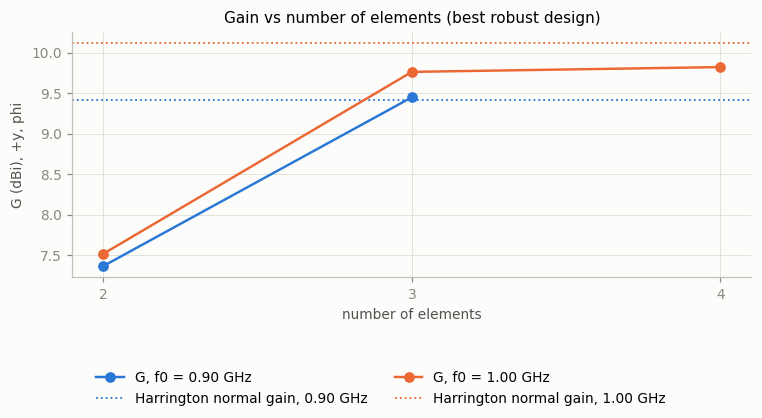

In [5]:
rows = []
for f in (0.9, 1.0):
    gn = harrington_db(f)[0]
    a2 = [r for r in A2 if r['alpha_factor'] == 1.0 and r['best_config'] is True and abs(r['f_GHz'] - f) < 1e-9]
    if a2:
        b = max(a2, key=lambda r: r['G'])
        rows.append(dict(K=2, f0=f, geometry=f"d = {b['spacing_mm']:g} mm", fed=b['fed'], G=b['G_dBi'], G_rob=np.nan,
                         G_r=b['G_r_dBi'], D=b['D_dBi'], eta=b['eta_rad'], GN=gn, dG1=np.nan,
                         Gmax=np.nan, Q=np.nan, dESR=np.nan,
                         parts=f"{b['element_label']} (continuous)"))
    for camp, recs in (('B3', B3), ('B4', B4)):
        best = [r for r in recs if r['best_fed'] and abs(r['f0_GHz'] - f) < 1e-9]
        if not best:
            continue
        b = max(best, key=lambda r: r['objective'])
        chk = next((c for c in checks[camp] if c['rank'] == 1 and abs(c['f0_GHz'] - f) < 1e-9), None)
        dg1 = np.nan
        if chk:
            g0 = next(r['G_dBi'] for r in chk['freq_rows'] if abs(r['offset_pct']) < 1e-9)
            dg1 = min(r['G_dBi'] - g0 for r in chk['freq_rows'] if abs(abs(r['offset_pct']) - 1.0) < 1e-9)
        rows.append(dict(K=b['n_elements'], f0=f, geometry='d = ' + mm(b['spacings_mm']) + ' mm',
                         fed=b['fed'], G=b['G_kit_dBi'], G_rob=b['G_robust_mean_dBi'], G_r=b['G_r_dBi'], D=b['D_dBi'],
                         eta=b['eta'], GN=gn, dG1=dg1, Gmax=b['G_max_dBi'],
                         Q=chk['Q_in'] if chk else np.nan, dESR=b['esr_esl_G_min_dBi'] - b['G_kit_dBi'],
                         parts=', '.join(f"{ld['port']} {ld['label']} (+-{100 * ld['tol_rel']:.0f}%)" for ld in b['loads'])))
print(f"{'K':>2s} {'f0':>5s} {'geometry':>22s} {'fed':>4s} {'G':>6s} {'G_rob':>6s} {'G_r':>6s} {'D':>6s} {'eta':>6s} "
      f"{'G-G_N':>6s} {'G_max':>6s} {'dG(1%)':>7s} {'Q_in':>5s} {'dG_ESR':>7s}  components")
for r in rows:
    print(f"{r['K']:2d} {r['f0']:5.2f} {r['geometry']:>22s} {r['fed']:>4s} {r['G']:6.2f} {r['G_rob']:6.2f} {r['G_r']:6.2f} "
          f"{r['D']:6.2f} {r['eta']:6.3f} {r['G'] - r['GN']:+6.2f} {r['Gmax']:6.2f} {r['dG1']:+7.2f} {r['Q']:5.0f} {r['dESR']:+7.2f}  {r['parts']}")
print('dG(1%): worst gain change at f0 +- 1 % (frozen parts); dG_ESR: worst change over ESR <= 0.3 Ohm, ESL <= 1 nH')
if rows:
    fig, ax = plt.subplots(figsize=(7, 3.8))
    for i, f in enumerate((0.9, 1.0)):
        sel = [r for r in rows if r['f0'] == f]
        if sel:
            ax.plot([r['K'] for r in sel], [r['G'] for r in sel], marker='o', ms=6, color=SERIES[i], label=f'G, f0 = {f:.2f} GHz')
            ax.axhline(harrington_db(f)[0], color=SERIES[i], ls=':', lw=1.2, label=f'Harrington normal gain, {f:.2f} GHz')
    ax.set_xticks([2, 3, 4]); ax.set_xlabel('number of elements'); ax.set_ylabel('G (dBi), +y, phi')
    ax.set_title('Gain vs number of elements (best robust design)')
    show(fig, 'G_vs_K.png', ncol=2)